# imports

In [16]:
import sys
import os
import json
import numpy as np
import scipy as sp
import pandas as pd

import importlib

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from utils import analysis_utils

from utils import ai_slob

In [17]:
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(analysis_utils)

importlib.reload(ai_slob)

<module 'utils.ai_slob' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/ai_slob.py'>

In [18]:
# specific

sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_worm import read_utils
sys.path.append(os.path.join(os.getcwd(), '../../../worm-control/src'))
from utils_worm_control import read_utils as read_utils_control

In [19]:
importlib.reload(read_utils)
importlib.reload(read_utils_control)

<module 'utils_worm_control.read_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/worm-2025-fieseler/notebooks/analysis/../../../worm-control/src/utils_worm_control/read_utils.py'>

# setup

In [20]:
ll = 'll00'
data_variant = 'gcamp'

In [21]:
# specific

model_variant = 'ss'
organism = 'worm'
manual = False
full = False

In [22]:
file_id = 19
save = False

# load

In [23]:
state_key, state_label = analysis_utils.get_plot_class(organism)
model_path = read_utils.get_model_path()

filename = analysis_utils.read_filename(organism, file_id)
metadata = (filename, model_path, model_variant, data_variant, manual, full)

# scores

In [24]:
((bom_spn, _, _, _, _, _, _),
 (hgm_spn, _, _, _, _, _, _)) = analysis_utils.read_predictions(*metadata)

neuron_scores = analysis_utils.assemble_scoress([bom_spn], [hgm_spn])

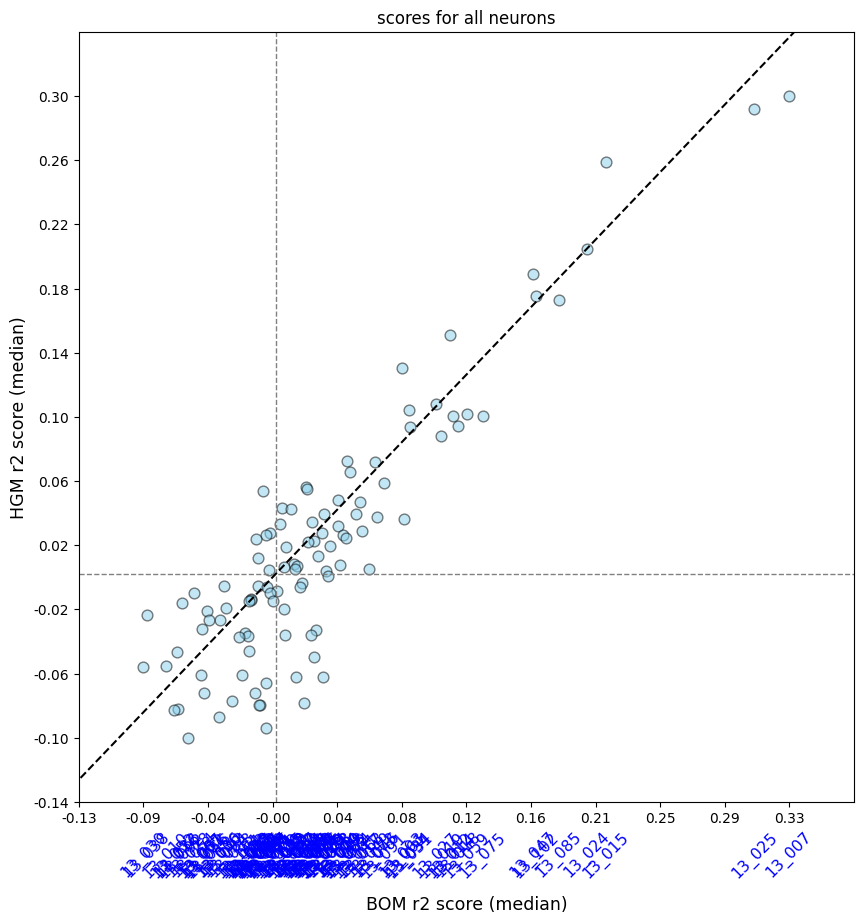

In [25]:
plot_utils.plot_performance_plot(
	neuron_scores, None,
	title='scores for all neurons', limits=None,
	save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_scores_all' if save else None
)

In [26]:
if organism == 'worm' and not all([key[0].isdigit() for key in neuron_scores]):
	plot_utils.plot_performance_plot(
		{key: neuron_scores[key] for key in neuron_scores.keys() if not key[0].isdigit()}, None,
		title='scores for ID\'d neurons', limits=None,
		save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_scores_id' if save else None
	)

# shuffle control

In [27]:
shuffles = sum(folder.startswith('shuffle_') for folder in os.listdir(os.path.join(read_utils_control.get_model_path(0), '..'))) - 1

In [28]:
boms_spn, hgms_spn = list(), list()
for shuffle_id in range(shuffles):
	((bom_spn, _, _, _, _, _, _),
	 (hgm_spn, _, _, _, _, _, _)) = analysis_utils.read_scores(filename, read_utils_control.get_model_path(shuffle_id), model_variant, data_variant, manual, full)
	boms_spn.append(bom_spn)
	hgms_spn.append(hgm_spn)

neuron_scores_shuffle = analysis_utils.assemble_scoress(boms_spn, hgms_spn)

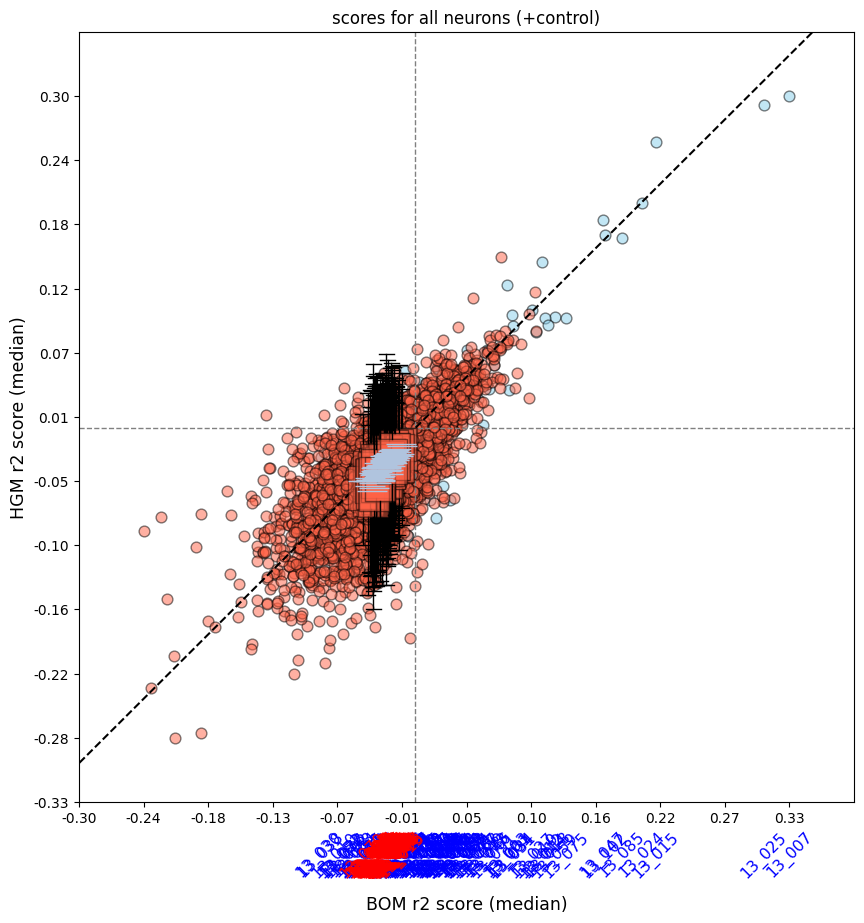

In [29]:
plot_utils.plot_performance_plot(
	neuron_scores, neuron_scores_shuffle,
	title='scores for all neurons (+control)', limits=None,
	horizontal_bps=False, force_medians=False, threshold=None,
	save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_scores_control' if save else None
)

In [30]:
if organism == 'worm' and not all([key[0].isdigit() for key in neuron_scores]):
	plot_utils.plot_performance_plot(
		{key: neuron_scores[key] for key in neuron_scores.keys() if not key[0].isdigit()},
		{key: neuron_scores_shuffle[key] for key in neuron_scores_shuffle.keys() if not key[0].isdigit()},
		title='scores for ID\'d neurons (+control)', limits=None,
		horizontal_bps=False, force_medians=False, threshold=None,
		save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_scores_id_control' if save else None
	)

In [31]:
percentiles_hgm = ai_slob.compute_neuron_percentiles(
    neuron_scores,
    neuron_scores_shuffle,
    model='hgm'
)

percentiles_bom = ai_slob.compute_neuron_percentiles(
    neuron_scores,
    neuron_scores_shuffle,
    model='bom'
)

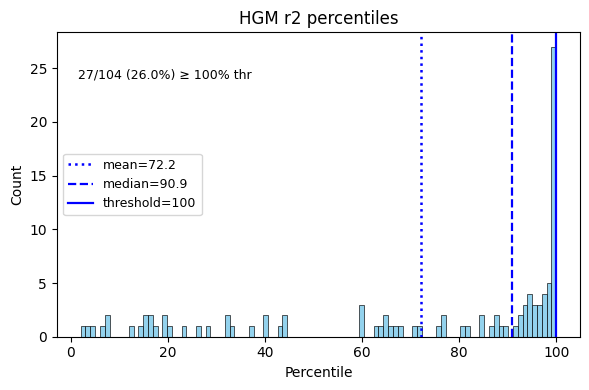

(<Figure size 600x400 with 1 Axes>,
 <Axes: title={'center': 'HGM r2 percentiles'}, xlabel='Percentile', ylabel='Count'>)

In [32]:
ai_slob.plot_percentile_hist(percentiles_hgm,
							 title='HGM r2 percentiles', threshold=100, bins=shuffles,
							 save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_hgm_percentiles' if save else None)

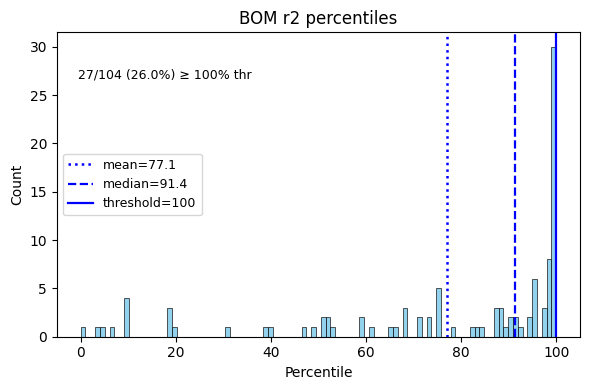

(<Figure size 600x400 with 1 Axes>,
 <Axes: title={'center': 'BOM r2 percentiles'}, xlabel='Percentile', ylabel='Count'>)

In [33]:
ai_slob.plot_percentile_hist(percentiles_bom,
							 title='BOM r2 percentiles', threshold=100, bins=shuffles,
							 save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_bom_percentiles' if save else None)

In [34]:
neuron_scores_significant_hgm = {key: value for key, value in neuron_scores.items() if percentiles_hgm[key] >= 100.0 and neuron_scores[key][1] > 0}
neuron_scores_significant_hgm = dict(sorted(neuron_scores_significant_hgm.items(), key=lambda x: x[1][1], reverse=True))

neuron_scores_significant_bom = {key: value for key, value in neuron_scores.items() if percentiles_bom[key] >= 100.0 and neuron_scores[key][0] > 0}
neuron_scores_significant_bom = dict(sorted(neuron_scores_significant_bom.items(), key=lambda x: x[1][0], reverse=True))

neuron_scores_significant = {key: value for key, value in neuron_scores_significant_hgm.items() if key in neuron_scores_significant_bom}
neuron_scores_significant = dict(sorted(neuron_scores_significant.items(), key=lambda x: x[1][1] - x[1][0], reverse=True))

In [35]:
p_values_sig_impr = ai_slob.empirical_p_value_two_sided(neuron_scores_significant, neuron_scores_shuffle, model='improvement')

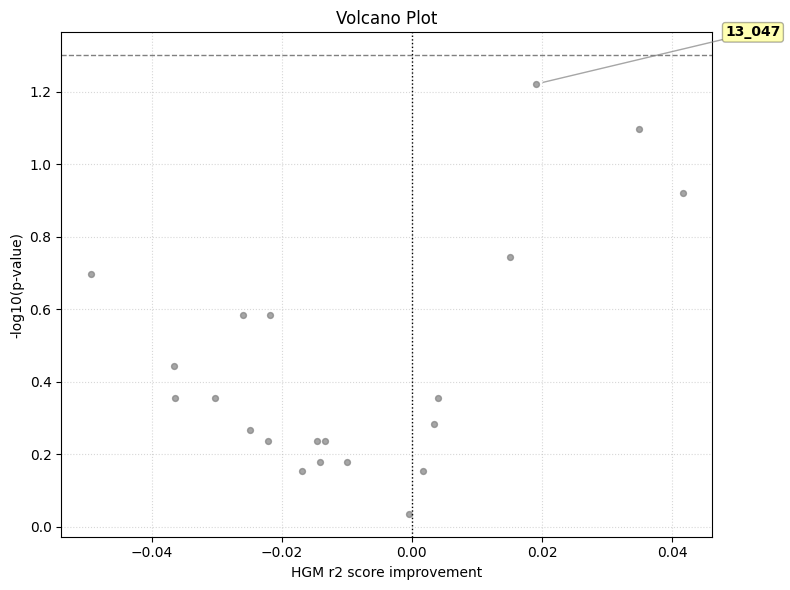

In [36]:
ai_slob.volcano_plot(neuron_scores_significant, p_values_sig_impr, model='improvement', n_label=None,
					 save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_impr_volcano' if save else None)

In [37]:
neuron_scores_significant_impr = {key: value for key, value in neuron_scores_significant.items() if p_values_sig_impr[key] == min(p_values_sig_impr.values())}
neuron_scores_significant_impr = dict(sorted(neuron_scores_significant_impr.items(), key=lambda x: x[1][1] - x[1][0], reverse=True))

In [38]:
os.makedirs(f'../../out/data/significant_neurons/{filename}/', exist_ok=True)

pd.DataFrame(neuron_scores_significant_hgm).to_pickle(f'../../out/data/significant_neurons/{filename}/{model_variant}_hgm.pkl')

pd.DataFrame(neuron_scores_significant_bom).to_pickle(f'../../out/data/significant_neurons/{filename}/{model_variant}_bom.pkl')

pd.DataFrame(neuron_scores_significant).to_pickle(f'../../out/data/significant_neurons/{filename}/{model_variant}_both.pkl')

pd.DataFrame(neuron_scores_significant_impr).to_pickle(f'../../out/data/significant_neurons/{filename}/{model_variant}_impr.pkl')

In [39]:
print(f'\'{'\', \''.join([neuron_label for neuron_label in neuron_scores_significant_impr.keys()])}\'')

'13_047'


In [40]:
print(f'\'{'\', \''.join([neuron_label for neuron_label in neuron_scores_significant_impr.keys() if not neuron_label[0].isdigit()])}\'')

''


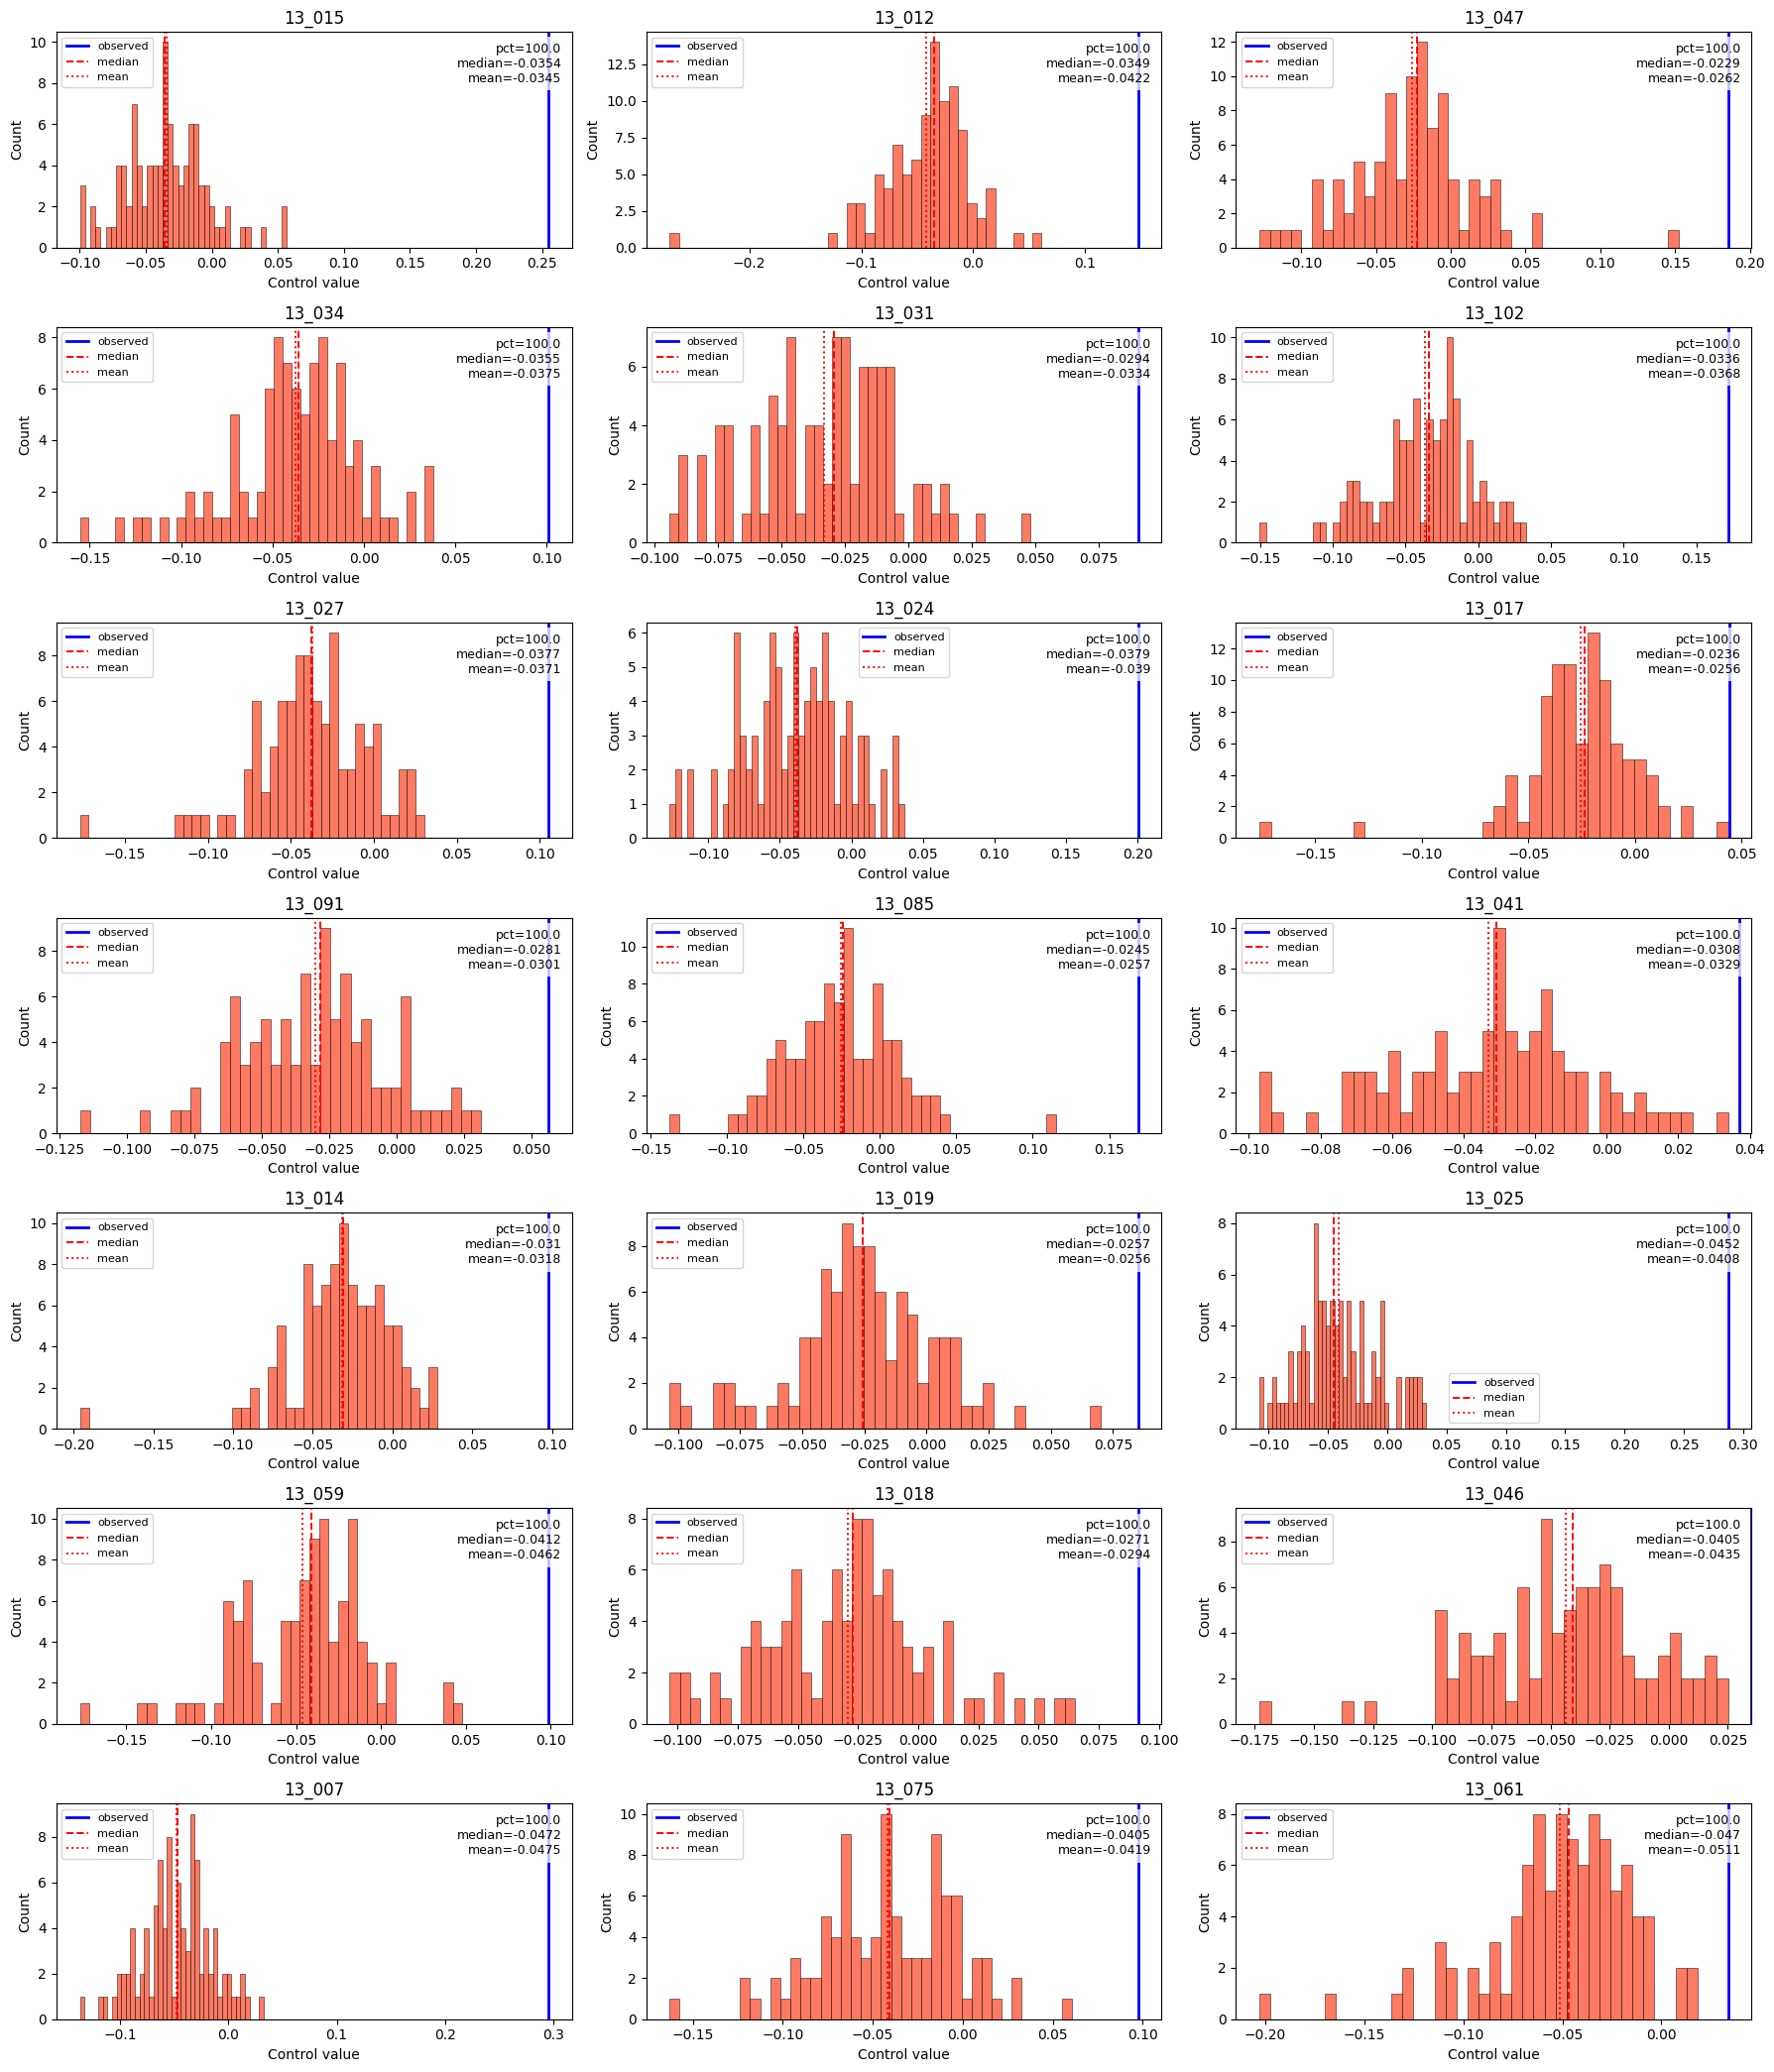

In [41]:
ai_slob.plot_control_histograms(neuron_scores, neuron_scores_shuffle, list(neuron_scores_significant.keys())[:50],
								model='hgm',
								save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_neurons' if save else None)
pass